# Wind influence on sea level at the Dutch coast

In [68]:
import sys
sys.path.append('../code')
import importlib

import os
import pandas as pd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from scipy.stats import linregress

import SeaLevelContrib as slc

In [69]:
# For higher resolution images on retina display screens
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('retina')

In [70]:
importlib.reload(slc)

<module 'SeaLevelContrib' from '/Users/dewilebars/Projects/SLBudget/notebooks/../code/SeaLevelContrib.py'>

### Read data from a sea level budget

In [71]:
data_dir = '../outputs/'

In [72]:
#df = pd.read_csv(f'{data_dir}older_results/SLBudget_Steric4000m_ERA5_1979_2018_withLocSteric.csv')
df = pd.read_csv(f'{data_dir}/slbudget_2026_08_12_ZSM_tide_gauge_1960_2025_ERA5_StericEN4_22_[500, 4000]m.csv')
df = df.set_index('time')
df[:10]

,Total,RegSteric,GloSteric,GIA,Glaciers,Antarctica,Greenland,TWS,Nodal,Wind,Pressure,Obs
time,,,,,,,,,,,,
1960,1.330705,-1.541471,1.172172,0.736667,1.192500,0.095833,0.115833,-0.508333,-0.052226,-2.170257,2.289987,0.889984
1961,5.242993,-1.491322,1.359791,0.773500,1.235000,0.101667,0.124167,-0.360000,-0.016606,2.857125,0.659672,7.656651
1962,3.536294,-2.773234,1.488711,0.810333,1.287500,0.105833,0.133333,-0.424167,0.076486,2.741321,0.090176,2.406651
1963,-2.557647,-3.986956,1.355248,0.847167,1.316667,0.111667,0.135000,-0.519167,0.216538,-2.616677,0.582866,-3.326683
1964,-1.558583,-1.368845,1.121032,0.884000,1.312500,0.115833,0.135833,-0.673333,0.387736,-2.333129,-1.140210,-1.276683
1965,4.271256,-2.742749,1.079551,0.920833,1.327500,0.121667,0.140000,-0.505833,0.570751,1.826379,1.533157,4.189984
1966,6.424515,-0.987514,1.134999,0.957667,1.353333,0.125833,0.148333,-0.325833,0.744918,1.321560,1.951217,7.139984
1967,10.359886,-0.849503,1.012791,0.994500,1.381667,0.131667,0.150833,-0.489167,0.890572,6.570755,0.565772,9.889984
1968,2.100664,-1.592064,0.807826,1.031333,1.407500,0.135000,0.160000,-0.618333,0.991266,-1.001241,0.779377,3.439984


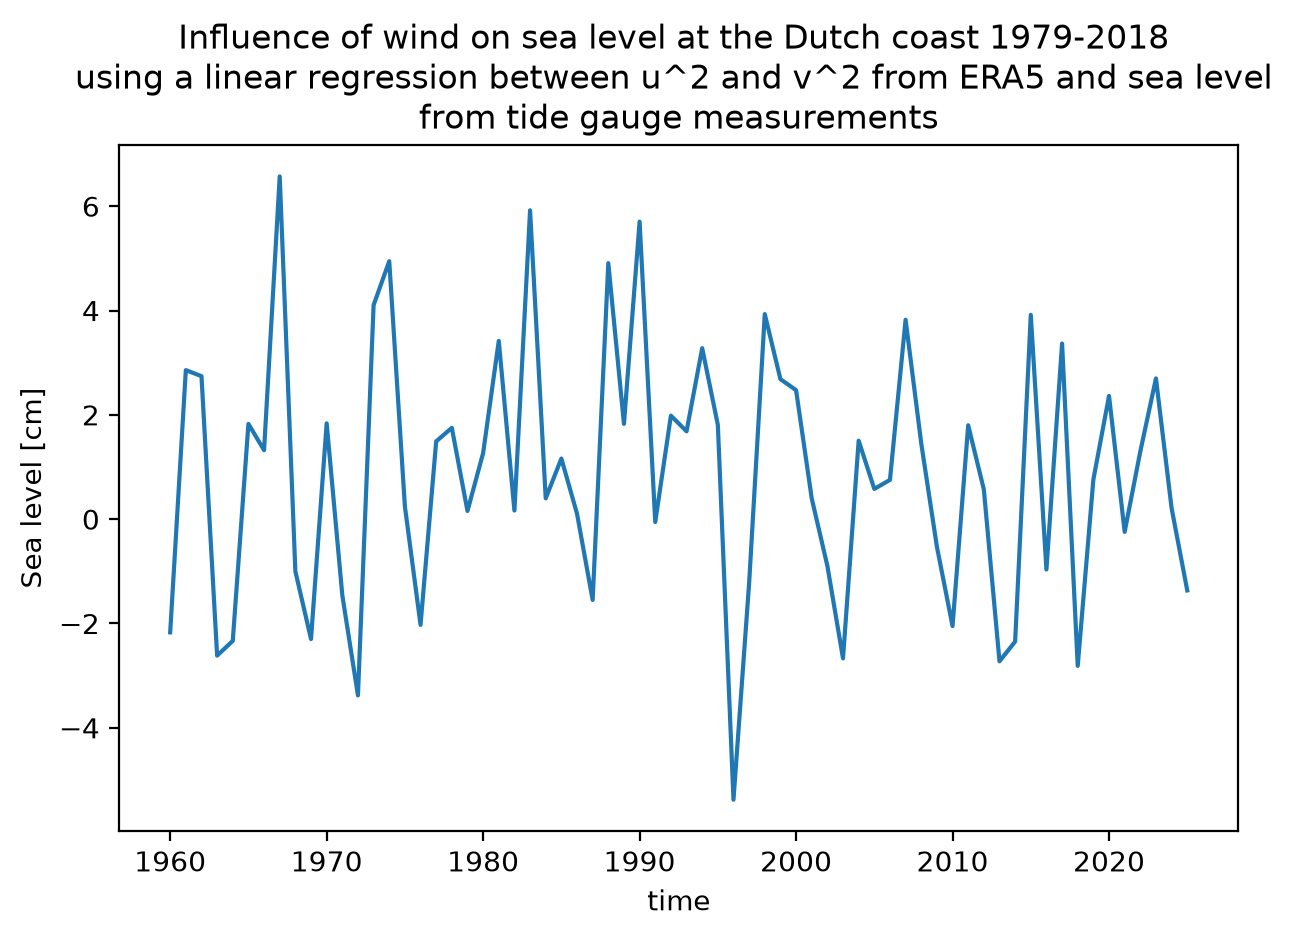

In [73]:
ax = df['Wind'].plot()
ax.set_ylabel('Sea level [cm]')
ax.set_title('Influence of wind on sea level at the Dutch coast 1979-2018 \n'+ 
             'using a linear regression between u^2 and v^2 from ERA5 and sea level \n'+
             'from tide gauge measurements')
plt.tight_layout()

#plt.savefig('../figures/WindInfluenceOnSeaLevelDutchCoast.pdf', dpi=150)

### Compare regression with GTSM and WAQUA

In [74]:
wind_pressure_df = pd.DataFrame(df['Wind'] + df['Pressure'], columns=['regression'])
wind_pressure_df['regression'] = wind_pressure_df['regression'] - wind_pressure_df['regression'].mean(axis=0)

In [75]:
tg_id = [20, 22, 23, 24, 25, 32] # Zeespiegelmonitor stations

In [76]:
# Read WAQUA (Data from Nina)
for idx, i in enumerate(tg_id):
    if idx == 0:
        waqua_df = slc.make_waqua_df(i).rename(columns={'WindPressure':i})
    else:
        waqua_df[i] = slc.make_waqua_df(i).rename(columns={'WindPressure':i})
waqua_df['mean'] = waqua_df.mean(axis=1)

In [77]:
# Read GTSM (Data from Fedor, ZSM 2022)
for idx, i in enumerate(tg_id):
    if idx == 0:
        gtsm_df = slc.make_gtsm_df(i,'surge').rename(columns={'WindPressure':i})
    else:
        gtsm_df[i] = slc.make_gtsm_df(i,'surge').rename(columns={'WindPressure':i})
gtsm_df['mean'] = gtsm_df.mean(axis=1)

Remark: GTSM 'surge' and 'waterlevel' variables are almost exactly the same for yearly averages

In [78]:
# Read new GTSM data (ZSM 2026)
for idx, i in enumerate(tg_id):
    if idx == 0:
        gtsm2_df = slc.make_gtsm2_df(i).rename(columns={'WindPressure':i})
    else:
        gtsm2_df[i] = slc.make_gtsm2_df(i).rename(columns={'WindPressure':i})
gtsm2_df['mean'] = gtsm2_df.mean(axis=1)

In [79]:
wind_pressure_df['gtsm2'] = gtsm2_df['mean'] - gtsm2_df['mean'].mean()
wind_pressure_df['waqua'] = waqua_df['mean'] - waqua_df['mean'].mean()
wind_pressure_df['gtsm'] = gtsm_df['mean'] - gtsm_df['mean'].mean()


In [80]:
wind_pressure_df.loc[1979:2016]

,regression,gtsm2,waqua,gtsm
time,,,,
1979,0.460750,-0.539254,-1.275267,-0.743842
1980,0.610100,-0.989254,-0.696432,-1.105402
1981,2.975170,2.327412,2.470170,2.281723
1982,-1.046895,-0.272588,0.243159,-0.369823
1983,4.542577,3.344079,3.863600,3.277852
1984,-0.058668,-1.305921,-1.005030,-1.381284
1985,0.212371,-0.839254,-1.251344,-0.933006
1986,-0.849941,-0.305921,1.098748,-0.394963
1987,-3.024897,-3.039254,-2.543348,-3.120164


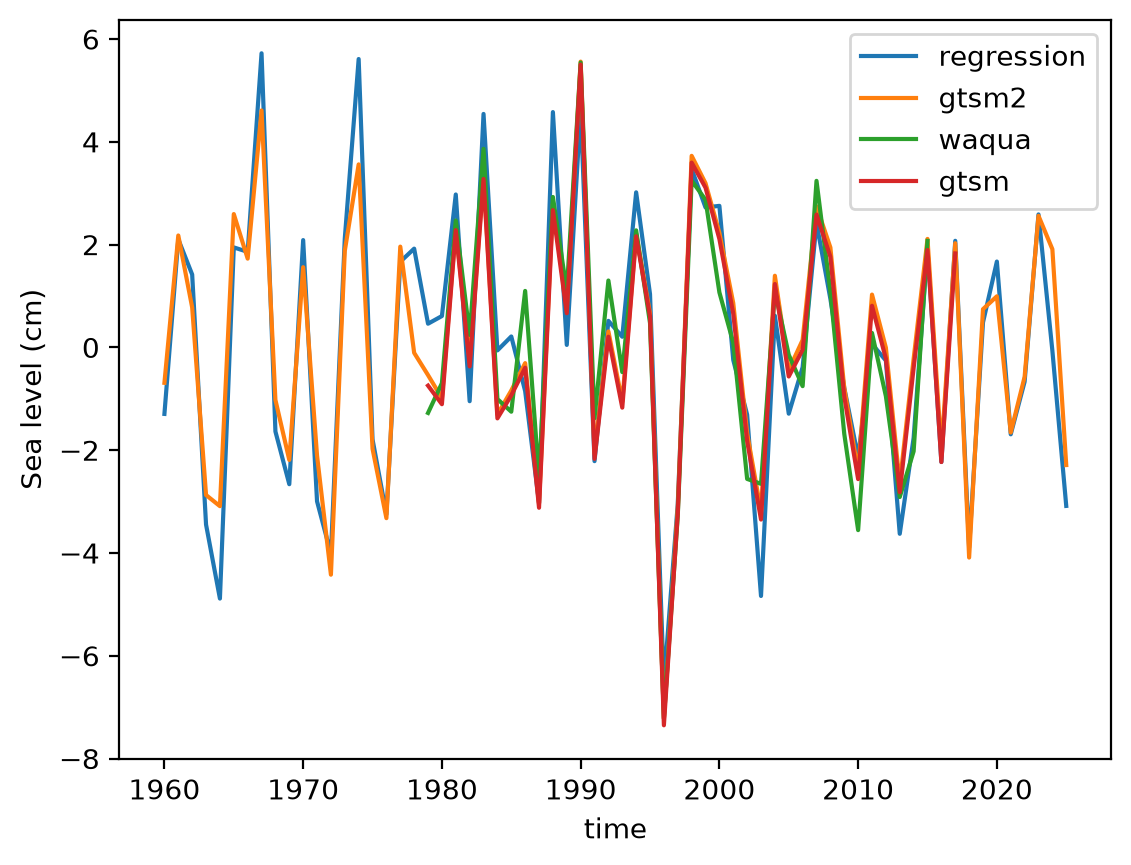

In [81]:
wind_pressure_df.plot()
plt.ylabel('Sea level (cm)');

<Axes: xlabel='time'>

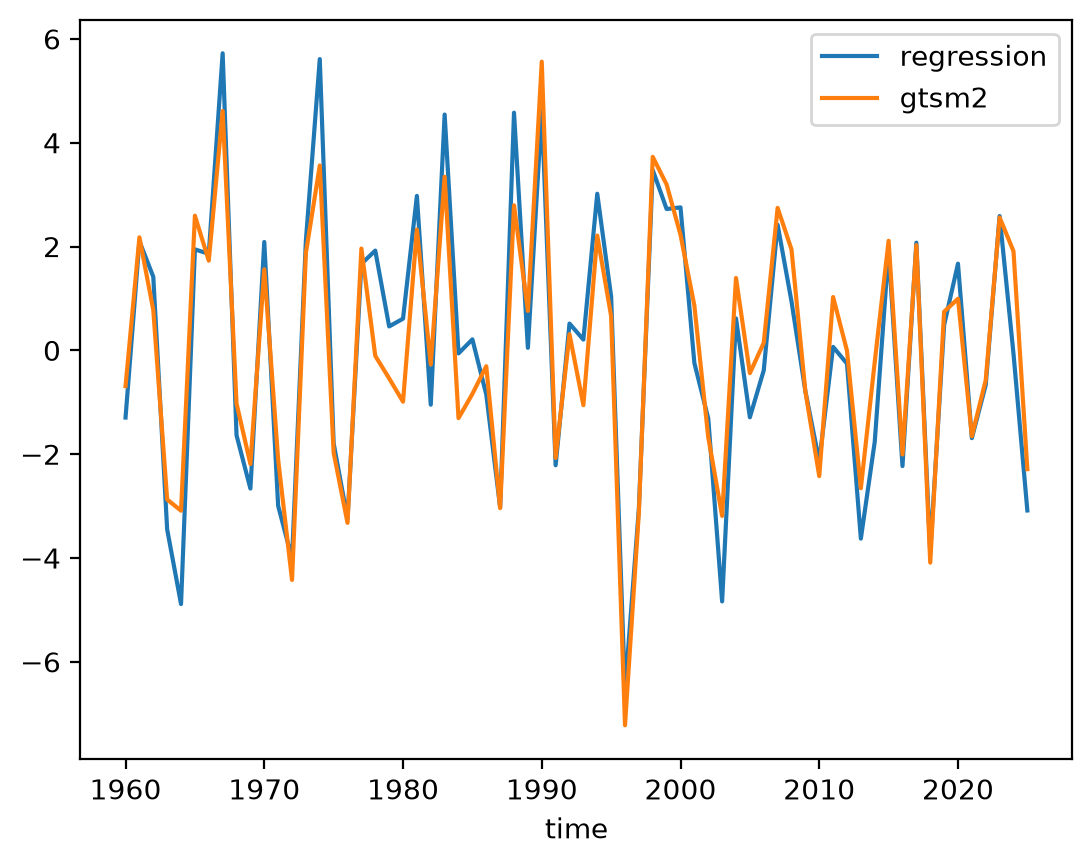

In [82]:
wind_pressure_df[["regression","gtsm2"]].plot()

In [148]:
wind_pressure_ra_df = wind_pressure_df.rolling(20, center=True).mean()
wind_pressure_std_df = wind_pressure_df.rolling(20, center=True).std()

Text(0.5, 1.0, 'Results with a 20 year running average')

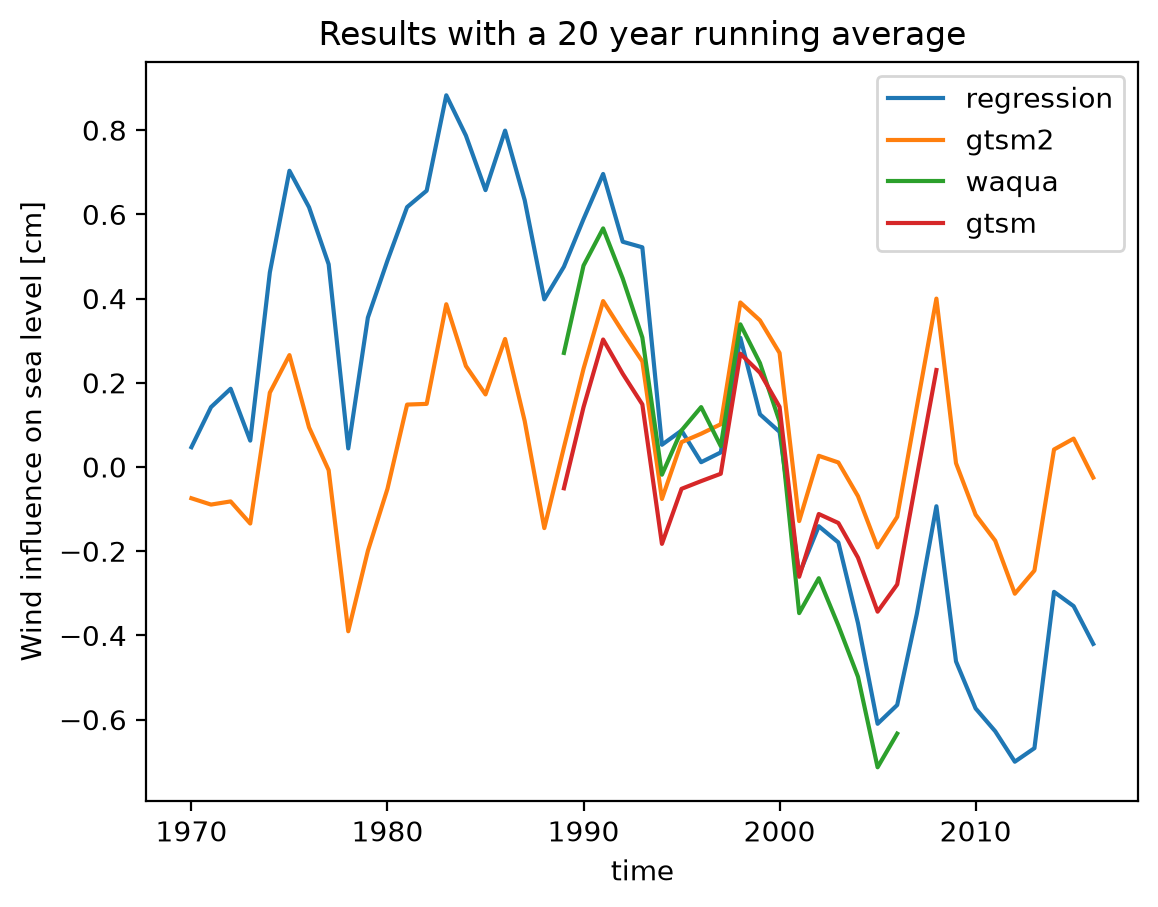

In [152]:
wind_pressure_ra_df.plot()
plt.ylabel('Wind influence on sea level [cm]')
plt.title('Results with a 20 year running average')

<Axes: xlabel='time'>

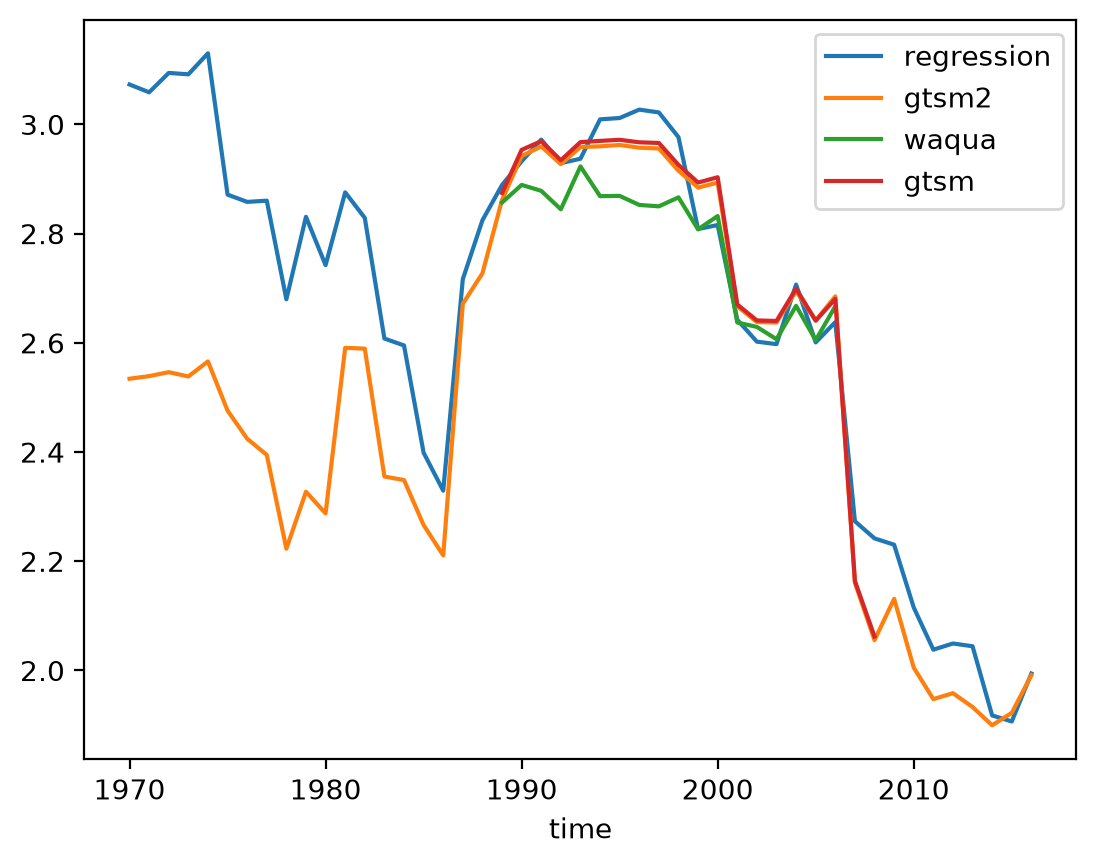

In [85]:
wind_pressure_std_df.plot()

### Compare sea level changes with wind

In [142]:
annual_wind_df = slc.make_wind_df(52.7, 4.2, "ERA5")
annual_wind_df = annual_wind_df.loc[1960:]

found point 52.75 4.25


In [143]:
annual_wind_df

,u,v,speed,direction,u2,v2,pres,ibe
t,,,,,,,,
1960,1.080270,0.853508,2.923962,2.136552,4.567991,4.665243,-273.062500,2.702415
1961,2.498555,0.910960,3.356362,2.273577,11.682797,3.201336,-26.578125,0.263014
1962,2.387261,-0.068507,3.062329,4.147897,10.382490,1.636013,66.484375,-0.658005
1963,0.847530,1.079780,3.163622,1.809646,3.385637,4.181029,-15.114583,0.149562
1964,1.345425,0.374689,2.453834,1.437934,2.329378,0.822928,249.244797,-2.466744
...,...,...,...,...,...,...,...,...
2021,1.821779,0.235049,3.157302,3.204485,6.388302,1.041620,84.234375,-0.833673
2022,1.889099,1.041333,3.723463,2.766059,11.572761,7.875030,156.963547,-1.553457
2023,2.417040,0.916413,3.978429,1.907226,12.581496,5.006729,-124.401039,1.231146


In [144]:
annual_wind_ra_df = annual_wind_df.rolling(20, center=True).mean()
annual_wind_std_df = annual_wind_df.rolling(20, center=True).std()

<Axes: xlabel='t'>

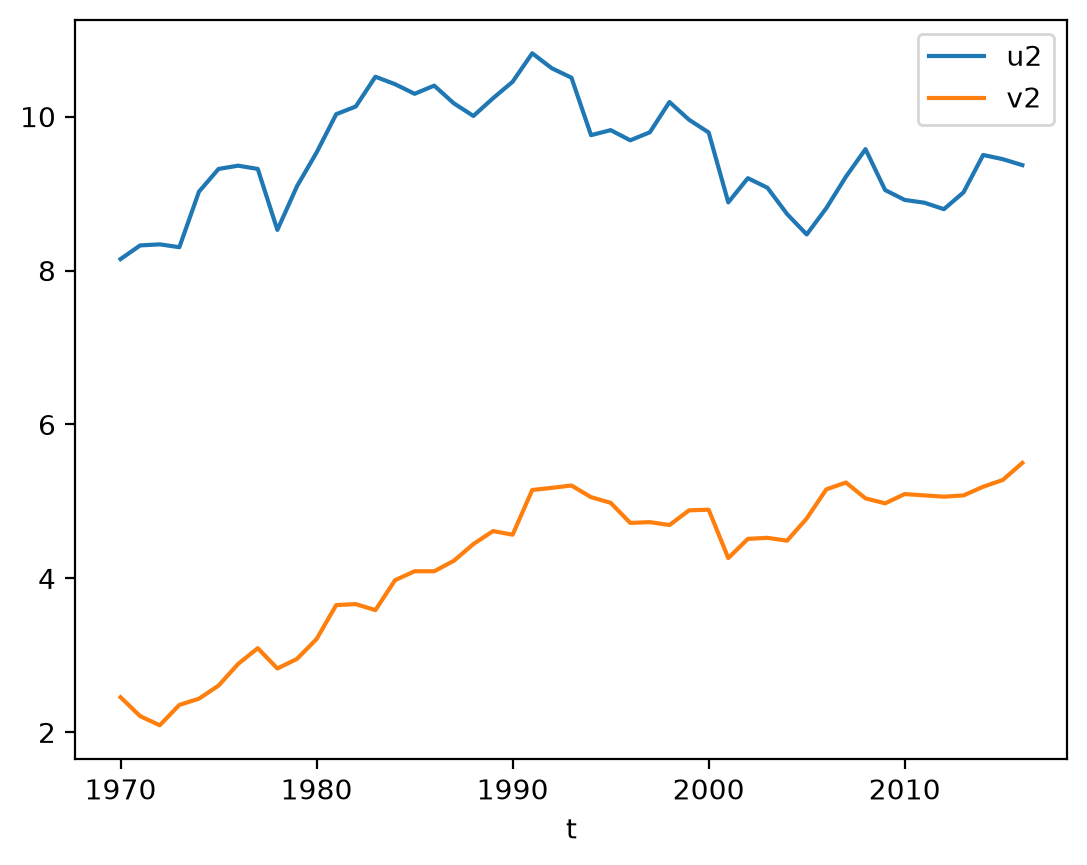

In [145]:
annual_wind_ra_df[["u2","v2"]].plot()

<Axes: xlabel='t'>

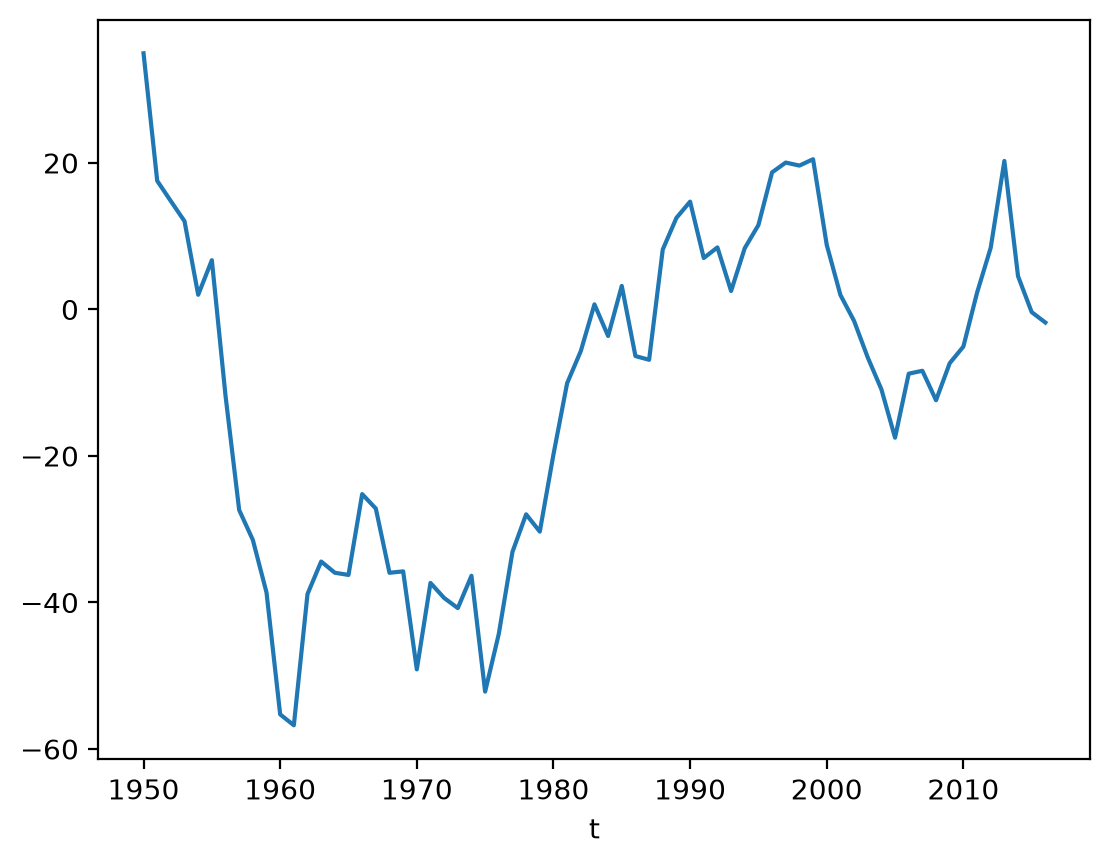

In [111]:
annual_wind_ra_df["pres"].plot()

In [103]:
wind_pressure_scalled_df = wind_pressure_df.div(annual_wind_df["u2"].loc[1960:],axis=0)

<Axes: xlabel='time'>

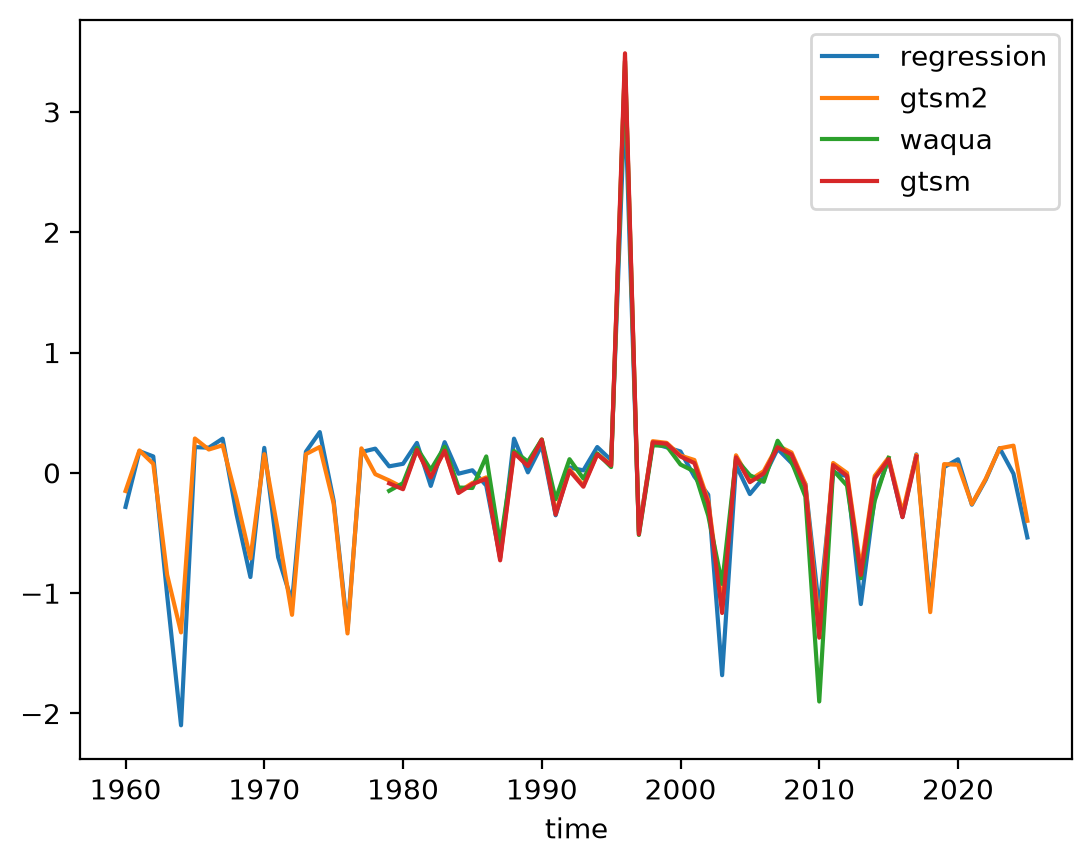

In [105]:
wind_pressure_scalled_df.plot()

In [119]:
#wind_pressure_df["regression"].join(annual_wind_df, how='inner')
df_c = annual_wind_df.join(wind_pressure_df["regression"], how='inner')
df_c = df_c.rename(columns={"regression":"height"})

In [122]:
df_c.index.names = ['year']
linear_fit, names = slc.linear_model_zsm(df_c, with_trend=False, with_nodal=False, 
                                         with_wind=True, with_pres=True, with_ar=False)

In [123]:
linear_fit.params[:]

const   -4.541402
x1       0.607167
x2      -0.271061
x3      -0.006290
dtype: float64

In [124]:
mod = np.array(linear_fit.params[:]) * np.array(linear_fit.model.exog[:,:])

In [137]:
wpn_ef_df = pd.DataFrame(index=df_c.index)

wpn_ef_df['u2'] = mod[:,1]
wpn_ef_df['v2'] = mod[:,2]
wpn_ef_df['Pressure'] = mod[:,3]
wpn_ef_df['sum'] = mod[:,1] + mod[:,2] + mod[:,3]

<Axes: xlabel='year'>

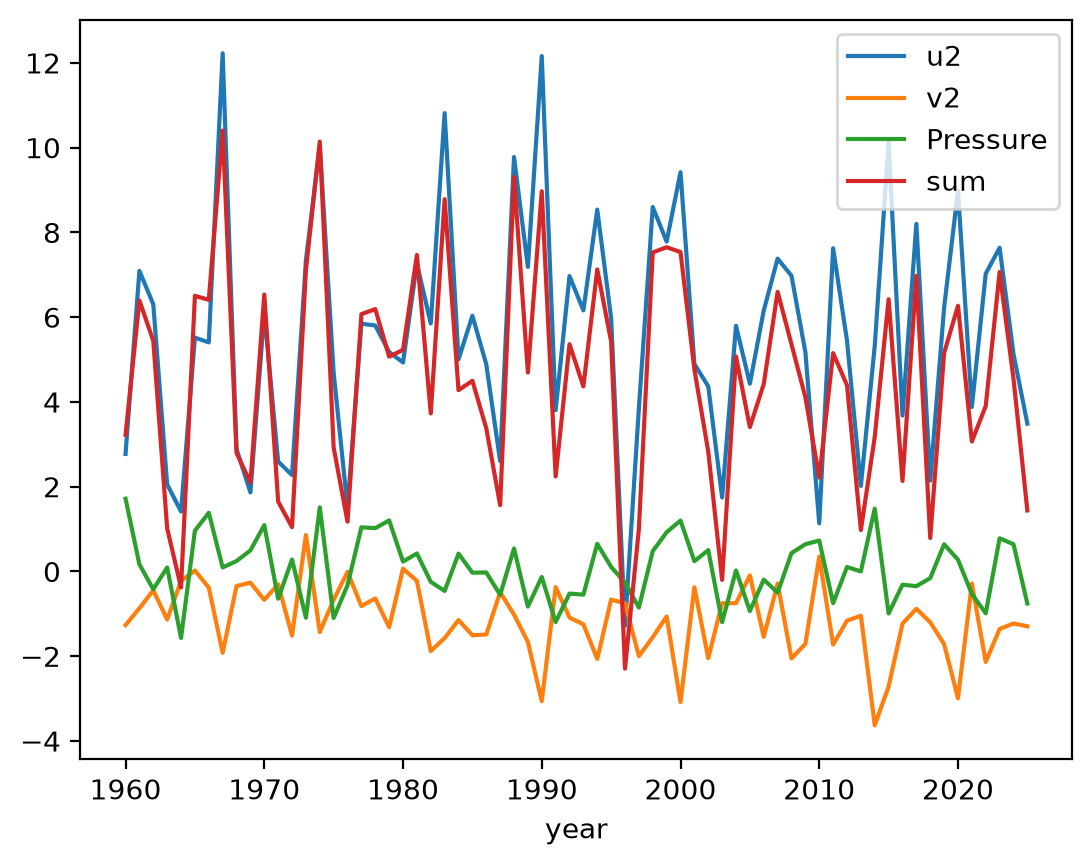

In [139]:
wpn_ef_df.plot()

In [140]:
wpn_ef_ra_df = wpn_ef_df.rolling(20, center=True).mean()
wpn_ef_ra_df = wpn_ef_ra_df-wpn_ef_ra_df.iloc[10]
 

<Axes: xlabel='year'>

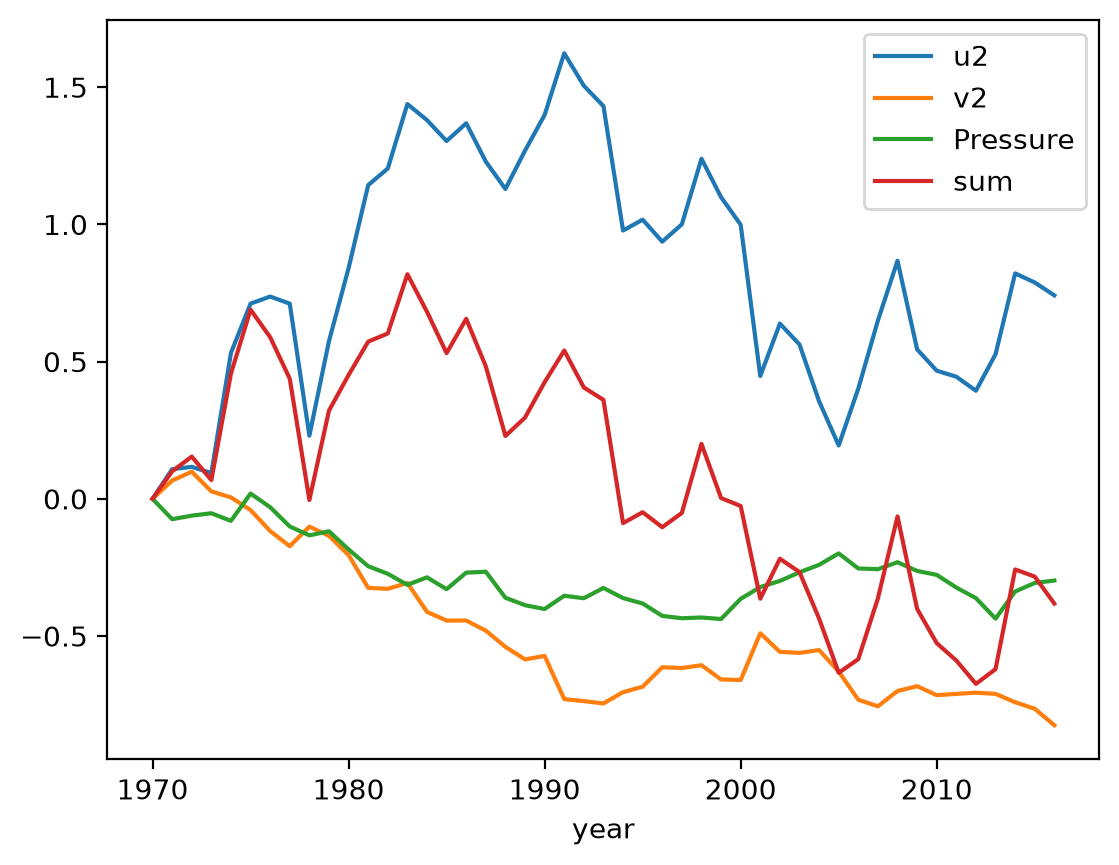

In [141]:
wpn_ef_ra_df.plot()

For the interannual variability, the zonal wind is dominant but for the low frequency variability all three drivers are almost equaly important. 

### Plot differences

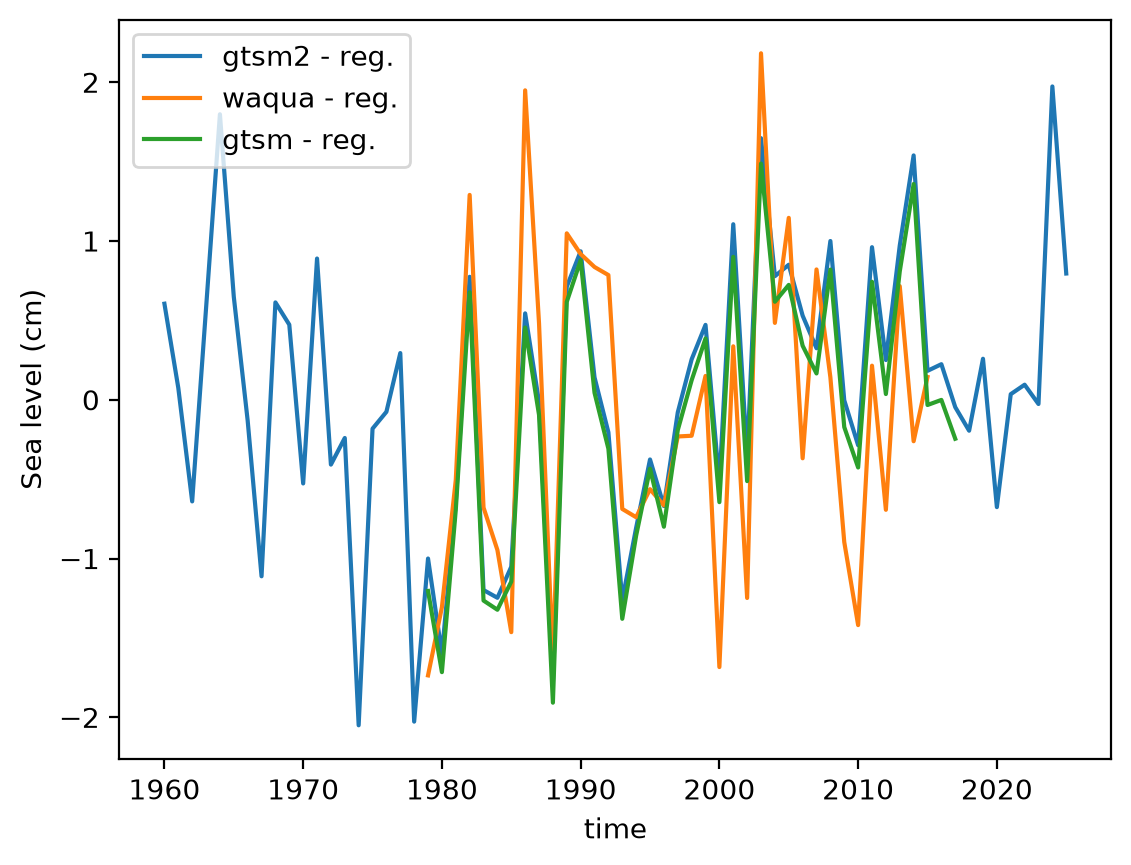

In [86]:
diff_df = wind_pressure_df.copy()
diff_df['waqua'] = diff_df['waqua'] - diff_df['regression']
diff_df['gtsm'] = diff_df['gtsm'] - diff_df['regression']
diff_df['gtsm2'] = diff_df['gtsm2'] - diff_df['regression']
del(diff_df['regression'])
diff_df.rename(columns={'waqua':'waqua - reg.',
                        'gtsm':'gtsm - reg.', 
                        'gtsm2':'gtsm2 - reg.'}).plot()
plt.ylabel('Sea level (cm)');

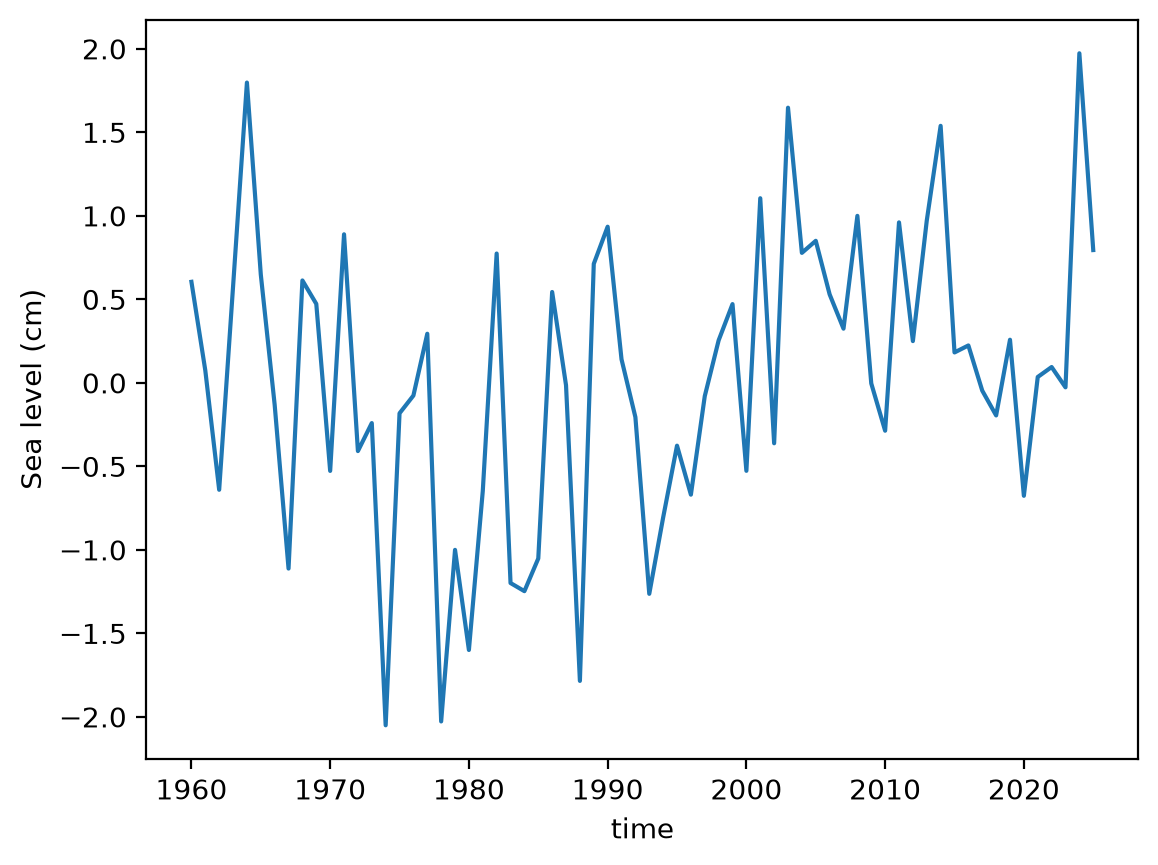

In [87]:
diff_df['gtsm2'].plot()
plt.ylabel('Sea level (cm)');

### Compute linear trends

In [88]:
# Compute on the full period
for col in wind_pressure_df.columns:
    print(f'Linear trend (mm/y) in {col}:')
    lin_trend = linregress(wind_pressure_df.index[:], 
                           wind_pressure_df[col][:]*10)  # Convert from cm to mm
    print(lin_trend.slope)

Linear trend (mm/y) in regression:
-0.13906013101398956
Linear trend (mm/y) in gtsm2:
-0.026013290192394654
Linear trend (mm/y) in waqua:
nan
Linear trend (mm/y) in gtsm:
nan


The linear trend is very sensitive to the method used to compute the wind effect on sea level

In [89]:
# Compute on the common period
wind_pressure_sel_df = wind_pressure_df.loc[1979:2015]

for col in wind_pressure_df.columns:
    print(f'Linear trend (mm/y) in {col}:')
    lin_trend = linregress(wind_pressure_sel_df.index[:], 
                           wind_pressure_sel_df[col][:]*10)  # Convert from cm to mm
    print(lin_trend.slope)

Linear trend (mm/y) in regression:
-0.5515644506408336
Linear trend (mm/y) in gtsm2:
-0.08123913387071283
Linear trend (mm/y) in waqua:
-0.43683508020150486
Linear trend (mm/y) in gtsm:
-0.11291907576139316
